# Idea 2 - Innovation: Declining or Recombining?

**The disagreement (Second Machine Age, ch. 5).** Gordon and Cowen argue that
the great inventions were one-time events and the low-hanging fruit is gone.
Weitzman, Romer and Arthur argue that ideas are building blocks rather than
fruit: blocks are not consumed when used, so every new one raises the number of
possible recombinations. Brynjolfsson and McAfee side with the second camp.

**The empirical wedge.** Both camps agree output growth slowed after 1970;
they disagree about why. That disagreement is testable as a ratio. If ideas are
a depleting stock, the research effort needed to sustain a given rate of
progress must rise over time. If recombination keeps replenishing the stock,
it need not. So we measure both sides of the ledger:

1. **The input.** Real R&D and software investment, and their share of GDP.
2. **The output.** Total factor productivity growth, by decade.
3. **The ratio.** Productivity growth per unit of research input, which is the
   Bloom-Jones-Van Reenen "research productivity" statistic in crude form.
4. **The composition.** Whether the capital stock is shifting toward the
   recombinable inputs Weitzman's model is about.

A falling ratio does not settle the argument on its own, and the closing
section says exactly what it cannot show. It does establish the price of the
recombination view: if blocks accumulate, each block is buying less.

**Data.** BEA NIPA Tables 5.3.3, 5.3.4 and 5.3.5, plus FRED for GDP and
productivity. No patent data: PatentsView retired its keyless API, and its
replacement will not page eight million records from a notebook.

In [1]:
import sys, pathlib, warnings, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

_here = pathlib.Path.cwd()
for _cand in [_here, *_here.parents]:
    if (_cand / "common" / "stacklib.py").exists():
        sys.path.insert(0, str(_cand / "common"))
        break
import stacklib as sl
importlib.reload(sl)

warnings.filterwarnings("ignore", category=FutureWarning)
print("stacklib version:", sl.__version__)

DIRS = sl.dirs_for("02_innovation_declining_or_recombining")
KEYS = sl.load_keys()
sl.apply_theme()

BEA = sl.require(KEYS, "BEA")
FRED = sl.require(KEYS, "FRED")
BASE_YEAR = 1970

stacklib version: 0.3.0
Keys loaded from .env: BEA, BLS, CENSUS, FRED


## 1. The input side: what the economy spends on making ideas

BEA Table 5.3.5 gives investment in current dollars, 5.3.3 gives quantity
indexes. Intellectual property products is the aggregate of software, R&D and
artistic originals: the closest thing the accounts have to "building blocks."

In [2]:
inv_cur = sl.bea_nipa_table("T50305", BEA, frequency="A", cache_dir=DIRS["data"])
inv_qty = sl.bea_nipa_table("T50303", BEA, frequency="A", cache_dir=DIRS["data"])

print("\nLines available in Table 5.3.5:")
for _, row in inv_cur[["line", "description"]].drop_duplicates().iterrows():
    print("   %4d  %s" % (row["line"], row["description"]))

BEA T50305: 2403 rows, 31 lines, 1947-2025
BEA T50303: 2403 rows, 31 lines, 1947-2025

Lines available in Table 5.3.5:
      1  Private fixed investment
      2  Nonresidential
      3  Structures
      4  Commercial and health care
      5  Manufacturing
      6  Power and communication
      7  Mining exploration, shafts, and wells
      8  Other structures
      9  Equipment
     10  Information processing equipment
     11  Computers and peripheral equipment
     12  Other
     13  Industrial equipment
     14  Transportation equipment
     15  Other equipment
     16  Intellectual property products
     17  Software
     18  Research and development
     19  Entertainment, literary, and artistic originals
     20  Residential
     21  Structures
     22  Permanent site
     23  Single family
     24  Multifamily
     25  Other structures
     26  Equipment
     27  Private fixed investment in structures
     28  Private fixed investment in new structures
     29  Nonresidential st

In [3]:
# Line numbers verified against the printout above (same structure as 5.3.3/5.3.4).
LINES = {
    "All fixed investment":     1,
    "Structures":               3,
    "Equipment":                9,
    "Computers":               11,
    "Intellectual property":   16,
    "Software":                17,
    "Research and development": 18,
}

# Table 5.3.5 is assumed to share the line numbering of 5.3.3 and 5.3.4. Assumed
# is not verified, and a wrong line number returns a plausible wrong series
# silently, so check the descriptions before using them.
EXPECT = {1: "private fixed investment", 3: "structures", 9: "equipment",
          11: "computers", 16: "intellectual property", 17: "software",
          18: "research and development"}
descs = dict(zip(inv_cur["line"], inv_cur["description"].astype(str).str.strip().str.lower()))
bad = {ln: descs.get(ln) for ln, word in EXPECT.items() if word not in (descs.get(ln) or "")}
if bad:
    raise AssertionError("Table 5.3.5 line numbers differ from 5.3.4. Mismatches: %s" % bad)
print("line numbering verified against Table 5.3.5\n")

CUR = sl.pick_lines(inv_cur, LINES)
QTY = sl.pick_lines(inv_qty, LINES)
print("\nCurrent-dollar investment, $bn:")
print(CUR.loc[[1970, 1990, 2010, int(CUR.index.max())]].round(1).to_string())

line numbering verified against Table 5.3.5

match All fixed investment     -> line   1  Private fixed investment
match Structures               -> line   3  Structures
match Equipment                -> line   9  Equipment
match Computers                -> line  11  Computers and peripheral equipment
match Intellectual property    -> line  16  Intellectual property products
match Software                 -> line  17  Software
match Research and development -> line  18  Research and development
match All fixed investment     -> line   1  Private fixed investment
match Structures               -> line   3  Structures
match Equipment                -> line   9  Equipment
match Computers                -> line  11  Computers and peripheral equipment
match Intellectual property    -> line  16  Intellectual property products
match Software                 -> line  17  Software
match Research and development -> line  18  Research and development

Current-dollar investment, $bn:
      All fixe

### Finding the productivity series rather than guessing its ID

FRED IDs change and retire. The search endpoint prints candidates with their
coverage so we choose deliberately; the fetch then tries a short ordered list
and reports which one it used.

In [4]:
print("=== candidates: total factor productivity ===")
print(sl.fred_search("total factor productivity united states", FRED, limit=10).to_string(index=False))
print("\n=== candidates: real GDP, annual ===")
print(sl.fred_search("real gross domestic product annual", FRED, limit=8).to_string(index=False))

=== candidates: total factor productivity ===
              id                                                                          title freq               units from   to  popularity
        CPIAUCSL   Consumer Price Index for All Urban Consumers: All Items in U.S. City Average    M Index 1982-1984=100 1947 2026          97
RTFPNAUSA632NRUG        Total Factor Productivity at Constant National Prices for United States    A        Index 2021=1 1954 2023          57
        AWHNONAG Average Weekly Hours of Production and Nonsupervisory Employees, Total Private    M               Hours 1964 2026          49
          AWHMAN Average Weekly Hours of Production and Nonsupervisory Employees, Manufacturing    M               Hours 1939 2026          42
         MFPNFBS                     Private Nonfarm Business Sector: Total Factor Productivity    A      Index 2017=100 1948 2025          30
          MFPPBS                             Private Business Sector: Total Factor Productivity 

In [5]:
def annual(s):
    a = s.groupby(s.index.year).mean()
    a.index = a.index.astype(int)
    return a

tfp_id, tfp_raw = sl.fred_first_available(
    ["RTFPNAUSA632NRUG",   # Penn World Table, TFP at constant national prices
     "MFPNFBS",            # BLS multifactor productivity, nonfarm business
     "OPHNFB"],            # fallback: output per hour, nonfarm business
    FRED, cache_dir=DIRS["data"])
gdp_id, gdp_raw = sl.fred_first_available(
    ["GDPCA", "GDPC1"], FRED, cache_dir=DIRS["data"])

TFP, GDP = annual(tfp_raw), annual(gdp_raw)
print("\nusing TFP series %s (%d-%d) and real GDP series %s"
      % (tfp_id, TFP.index.min(), TFP.index.max(), gdp_id))

FRED RTFPNAUSA632NRUG: 70 obs, 1954-01-01-2023-01-01
FRED GDPCA: 97 obs, 1929-01-01-2025-01-01

using TFP series RTFPNAUSA632NRUG (1954-2023) and real GDP series GDPCA


## Figure 1 - Research effort against the economy that funds it

All three series are indexed to the same base year and drawn on one log axis,
so the comparison is of growth rates rather than levels.

saved -> C:\Users\91838\Downloads\Stack_Article\02_innovation_declining_or_recombining\figures\fig1_research_inputs_vs_gdp.png


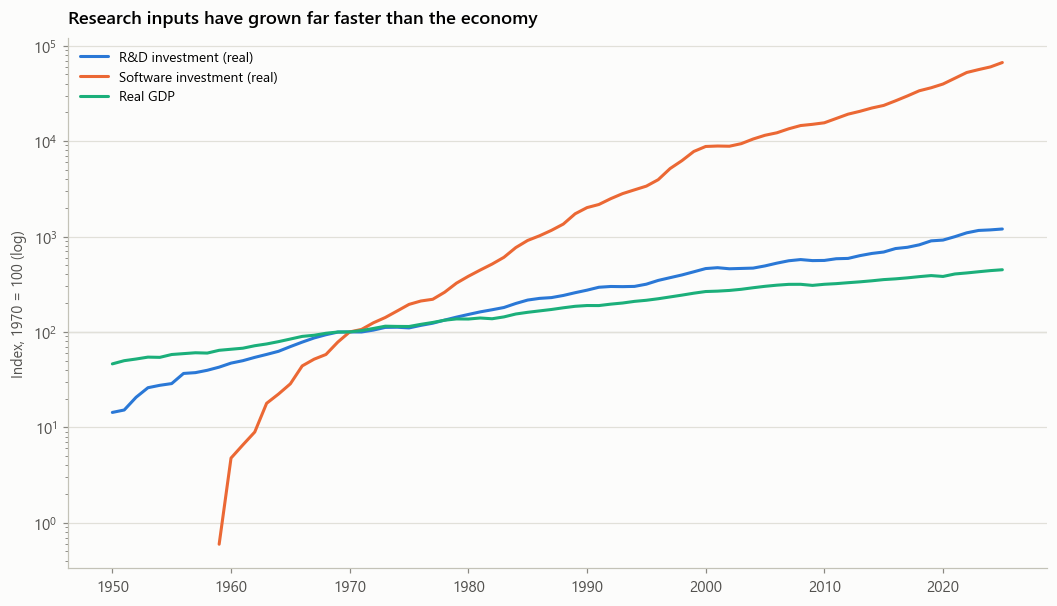

In [6]:
def rebase(s, year=BASE_YEAR):
    s = s.dropna()
    anchor = year if year in s.index else int(s.index.min())
    return s / s.loc[anchor] * 100.0

series1 = {
    "R&D investment (real)": rebase(QTY["Research and development"]),
    "Software investment (real)": rebase(QTY["Software"]),
    "Real GDP": rebase(GDP),
}
fig, ax = plt.subplots(figsize=(9.5, 5.4))
for (name, s), color in zip(series1.items(), sl.PALETTE[:3]):
    s = s[s.index >= 1950]
    ax.plot(s.index, s.values, color=color, lw=2.0, label=name)
ax.set_yscale("log")
ax.axhline(100, color=sl.INK["axis"], lw=0.8, zorder=0)
ax.set_ylabel("Index, %d = 100 (log)" % BASE_YEAR)
ax.set_title("Research inputs have grown far faster than the economy")
ax.legend(loc="upper left")
sl.save_fig(fig, "fig1_research_inputs_vs_gdp", DIRS)
plt.show()

## Figure 2 - The capital stock is shifting toward building blocks

Weitzman's model is about recombinable inputs. If his account describes the
modern economy, the share of investment going into intellectual property
should rise against structures and equipment. This is a composition question,
so the three shares are drawn as shares of the same total.

saved -> C:\Users\91838\Downloads\Stack_Article\02_innovation_declining_or_recombining\figures\fig2_investment_composition.png


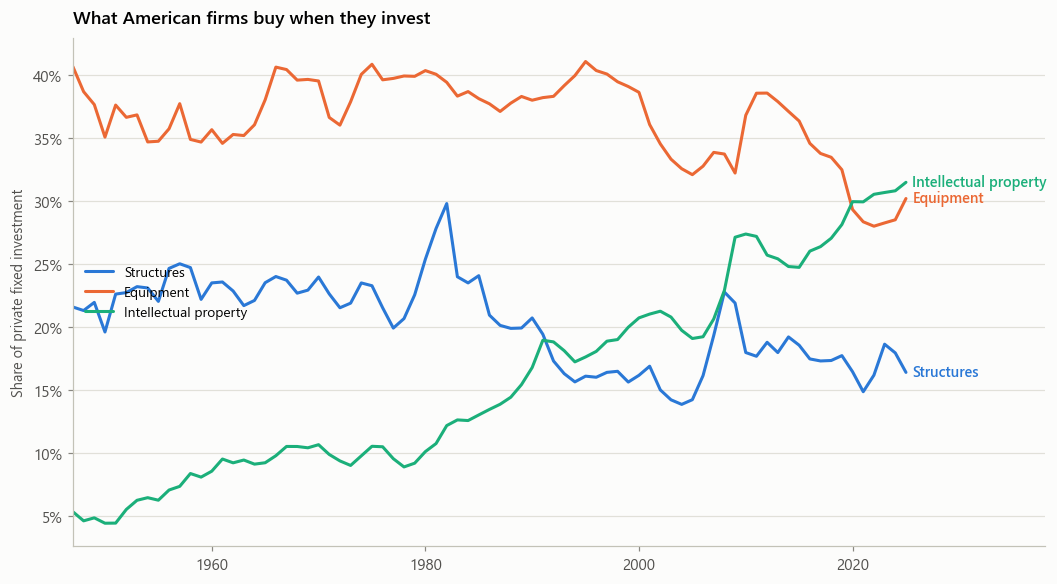

      Structures  Equipment  Intellectual property
year                                              
1950        19.6       35.1                    4.5
1970        24.0       39.5                   10.7
1990        20.7       38.0                   16.8
2010        18.0       36.8                   27.4
2025        16.4       30.2                   31.5


In [7]:
shares = pd.DataFrame({
    "Structures": CUR["Structures"] / CUR["All fixed investment"] * 100,
    "Equipment": CUR["Equipment"] / CUR["All fixed investment"] * 100,
    "Intellectual property": CUR["Intellectual property"] / CUR["All fixed investment"] * 100,
}).dropna()

fig, ax = plt.subplots(figsize=(9.5, 5.2))
for (name, color) in zip(shares.columns, sl.PALETTE[:3]):
    ax.plot(shares.index, shares[name].values, color=color, lw=2.0, label=name)
    sl.label_last(ax, shares[name], name, color)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: "%.0f%%" % v))
ax.set_ylabel("Share of private fixed investment")
ax.set_title("What American firms buy when they invest")
ax.set_xlim(shares.index.min(), shares.index.max() + 13)
ax.legend(loc="center left")
sl.save_fig(fig, "fig2_investment_composition", DIRS)
plt.show()
print(shares.loc[[1950, 1970, 1990, 2010, int(shares.index.max())]].round(1).to_string())

## Figure 3 - Input and output on separate axes

Research input and productivity growth belong on different scales, so they get
separate panels sharing one time axis rather than a second y axis. The top
panel is the effort; the bottom panel is what it bought.

saved -> C:\Users\91838\Downloads\Stack_Article\02_innovation_declining_or_recombining\figures\fig3_effort_and_payoff.png


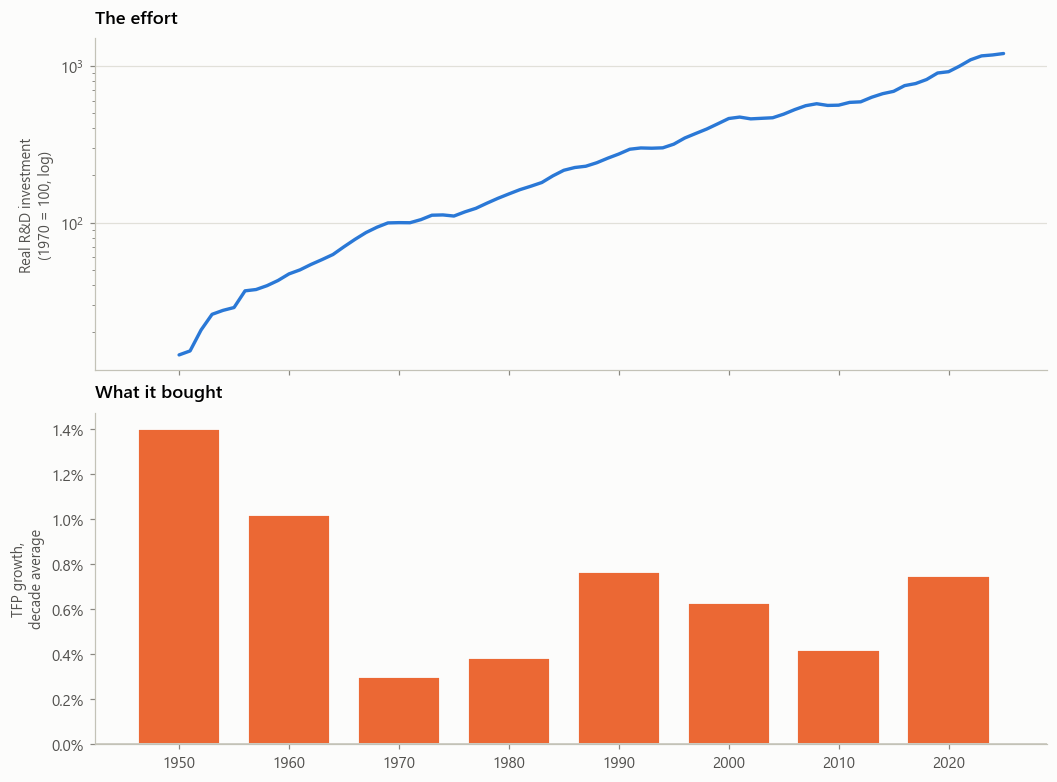

date
1950    1.40
1960    1.02
1970    0.30
1980    0.39
1990    0.76
2000    0.63
2010    0.42
2020    0.75


In [8]:
tfp_growth = (TFP.pct_change() * 100).dropna()
decade = (tfp_growth.index // 10) * 10
dec_growth = tfp_growth.groupby(decade).mean()
dec_growth = dec_growth[dec_growth.index >= 1950]

fig, axes = plt.subplots(2, 1, figsize=(9.5, 7.0), sharex=True,
                         gridspec_kw={"height_ratios": [1, 1]})
rd = rebase(QTY["Research and development"])
rd = rd[rd.index >= 1950]
axes[0].plot(rd.index, rd.values, color=sl.PALETTE[0], lw=2.2)
axes[0].set_yscale("log")
axes[0].set_ylabel("Real R&D investment\n(%d = 100, log)" % BASE_YEAR)
axes[0].set_title("The effort")

axes[1].bar(dec_growth.index, dec_growth.values, width=7.5,
            color=sl.PALETTE[1], edgecolor=sl.INK["surface"], linewidth=1.2)
axes[1].axhline(0, color=sl.INK["axis"], lw=1.0)
axes[1].yaxis.set_major_formatter(FuncFormatter(lambda v, _: "%.1f%%" % v))
axes[1].set_ylabel("TFP growth,\ndecade average")
axes[1].set_title("What it bought")
axes[1].grid(axis="y")
sl.save_fig(fig, "fig3_effort_and_payoff", DIRS)
plt.show()
print(dec_growth.round(2).to_string())

## Figure 4 - Research productivity

The headline. Dividing productivity growth by the real research input that
produced it gives growth per unit of effort. Bloom, Jones, Van Reenen and Webb
call this research productivity and find it falling across every domain they
measure. A ten-year average smooths the year-to-year noise in TFP.

saved -> C:\Users\91838\Downloads\Stack_Article\02_innovation_declining_or_recombining\figures\fig4_research_productivity.png


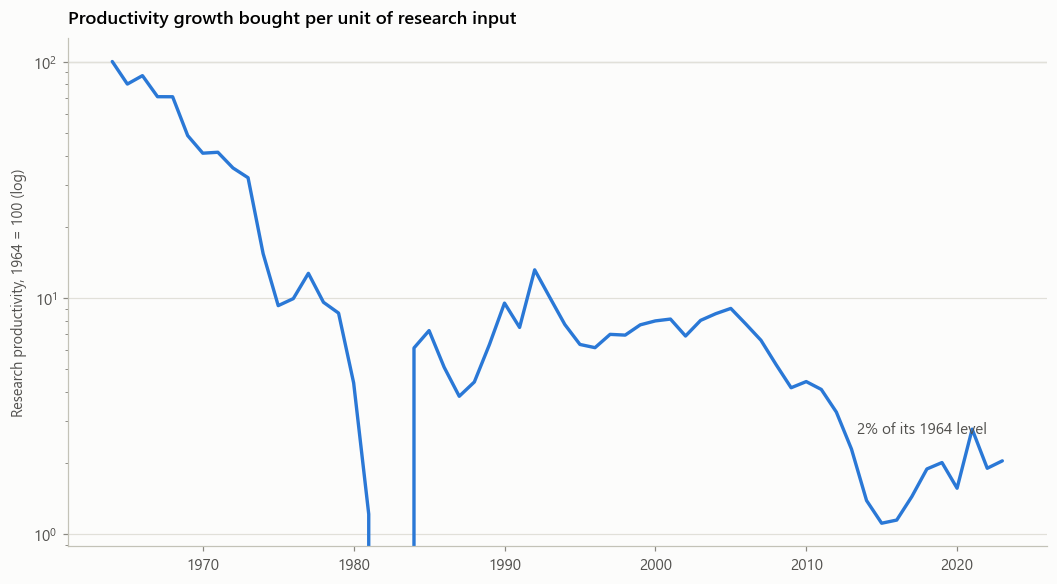

{'label': 'research productivity', 'start': 1964, 'end': 2023, 'n': 58, 'annual_pct': -5.223, 'r2': 0.68, 'halving_years': 12.921, 'slope_ln': -0.054, 'rss': 23.981}


In [9]:
common = tfp_growth.index.intersection(QTY["Research and development"].dropna().index)
rd_real = QTY["Research and development"].loc[common]
growth = tfp_growth.loc[common]

research_prod = (growth.rolling(10).mean() / rd_real.rolling(10).mean()).dropna()
research_prod = research_prod[research_prod.index >= 1960]
rp_idx = research_prod / research_prod.iloc[0] * 100

fig, ax = plt.subplots(figsize=(9.5, 5.2))
ax.plot(rp_idx.index, rp_idx.values, color=sl.PALETTE[0], lw=2.2)
ax.set_yscale("log")
ax.axhline(100, color=sl.INK["axis"], lw=0.8, zorder=0)
ax.set_ylabel("Research productivity, %d = 100 (log)" % int(rp_idx.index.min()))
ax.set_title("Productivity growth bought per unit of research input")
ax.annotate("%.0f%% of its %d level" % (rp_idx.iloc[-1], int(rp_idx.index.min())),
            xy=(rp_idx.index[-1], rp_idx.iloc[-1]), xytext=(-10, 18),
            textcoords="offset points", ha="right", color=sl.INK["secondary"], fontsize=10)
sl.save_fig(fig, "fig4_research_productivity", DIRS)
plt.show()

rp_fit = sl.loglinear_fit(rp_idx, "research productivity")
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in rp_fit.items()})

## Figure 5 - The arithmetic under the argument

This panel is arithmetic, not data, and the write-up will label it as such.
It draws the structural claim the two camps disagree about. Under the fruit
view the stock of available ideas is drawn down as it is used. Under the
building-block view, n components admit n(n-1)/2 pairs and far more triples,
so the space of possible innovations expands faster than the stock of blocks.
The disagreement is about which curve the economy is on.

saved -> C:\Users\91838\Downloads\Stack_Article\02_innovation_declining_or_recombining\figures\fig5_combinatorial_arithmetic.png


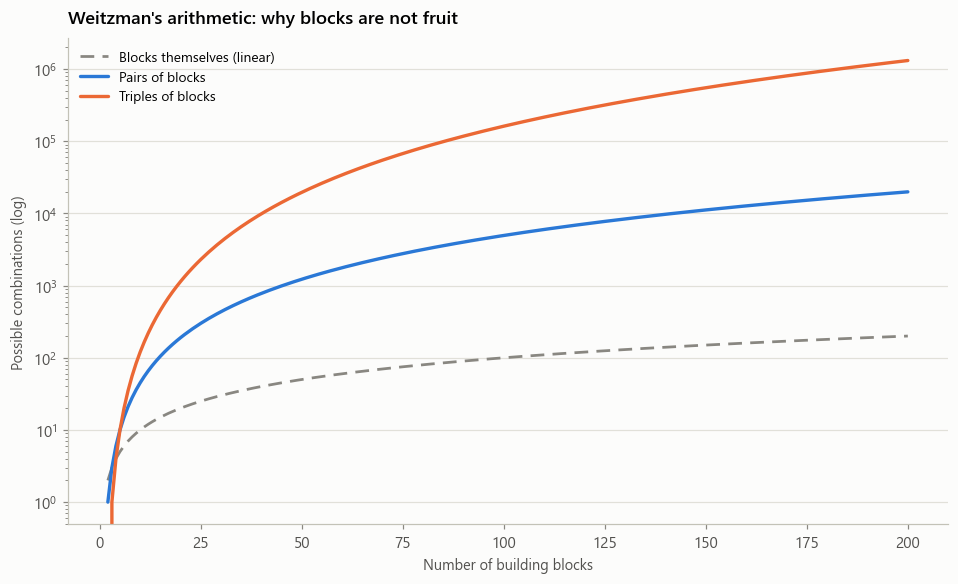

In [10]:
n = np.arange(2, 201)
pairs = n * (n - 1) / 2
triples = n * (n - 1) * (n - 2) / 6

fig, ax = plt.subplots(figsize=(8.6, 5.2))
ax.plot(n, n, color=sl.INK["muted"], lw=1.8, ls=(0, (5, 3)), label="Blocks themselves (linear)")
ax.plot(n, pairs, color=sl.PALETTE[0], lw=2.2, label="Pairs of blocks")
ax.plot(n, triples, color=sl.PALETTE[1], lw=2.2, label="Triples of blocks")
ax.set_yscale("log")
ax.set_xlabel("Number of building blocks")
ax.set_ylabel("Possible combinations (log)")
ax.set_title("Weitzman's arithmetic: why blocks are not fruit")
ax.legend(loc="upper left")
sl.save_fig(fig, "fig5_combinatorial_arithmetic", DIRS)
plt.show()

## 2. Bank the numbers

In [11]:
payload = {
    "stacklib_version": sl.__version__,
    "base_year": BASE_YEAR,
    "tfp_series_used": tfp_id,
    "gdp_series_used": gdp_id,
    "rd_real_growth_factor_since_base": float(rebase(QTY["Research and development"]).iloc[-1] / 100),
    "gdp_real_growth_factor_since_base": float(rebase(GDP).iloc[-1] / 100),
    "investment_shares_pct": shares.loc[[1950, 1970, 1990, 2010, int(shares.index.max())]].round(2).to_dict(orient="index"),
    "tfp_growth_by_decade_pct": dec_growth.round(3).to_dict(),
    "research_productivity_index": {int(k): round(float(v), 2) for k, v in rp_idx.items()},
    "research_productivity_end_vs_start_pct": float(rp_idx.iloc[-1]),
    "research_productivity_fit": rp_fit,
    "series_used": {k: int(v) for k, v in LINES.items()},
}
sl.write_findings(payload, DIRS)
shares.to_csv(pathlib.Path(DIRS["findings"]) / "investment_shares.csv")
dec_growth.to_frame("tfp_growth_pct").to_csv(pathlib.Path(DIRS["findings"]) / "tfp_growth_by_decade.csv")
rp_idx.to_frame("research_productivity_index").to_csv(pathlib.Path(DIRS["findings"]) / "research_productivity.csv")
print("\nDone. Five figures in figures/, numbers in findings/.")

findings -> C:\Users\91838\Downloads\Stack_Article\02_innovation_declining_or_recombining\findings\headline_numbers.json

Done. Five figures in figures/, numbers in findings/.


## Caveats to carry into the prose

1. **The ratio is crude.** Bloom, Jones, Van Reenen and Webb divide by the
   number of researchers, not by investment dollars, and they do it
   domain by domain. Real R&D investment is a serviceable proxy and no more.
   Quote the direction and the order of magnitude, not the decimal.
2. **TFP is a residual.** It is what is left after measured labour and capital
   inputs are accounted for, so every measurement problem in Idea 4 lands here.
   A falling residual can mean slowing ideas or worsening measurement.
3. **A falling ratio does not refute recombination.** Weitzman's own model
   predicts that growth becomes limited by the capacity to evaluate
   combinations, not by their supply. Falling research productivity is
   consistent with that, which is why Figure 2's composition evidence carries
   weight the ratio cannot.
4. **Investment is not the whole of research.** Federal basic research and
   university work are captured unevenly in business fixed investment.

**Send back:** the five PNGs, the FRED candidate tables printed in cell 5, the
decade growth table, and `findings/headline_numbers.json`. The FRED tables
matter this time: I want to see which series resolved before I write.